# Expectativas económicas a tres meses en el Perú, 2012–2025
## Modelo econométrico final

**Prácticas Preprofesionales II – Grupo 03** · Universidad Nacional Federico Villarreal
Castañeda Casallo, Belén Belinda · Ibias Mantilla, Jhon Kennedy · Quispe Soto, Emely Dayana · Venancio Romero, Daniel Wilder

### Objetivo
Determinar la dirección, la magnitud y la significación estadística de las asociaciones del **crecimiento interanual del PBI**, la **inflación subyacente mensual de bienes** y la **tasa interbancaria** con el **índice de expectativas de la economía a tres meses** en el Perú (enero de 2012–diciembre de 2025).

### Modelo
Se estima un **único modelo**: un modelo autorregresivo con dos rezagos de las expectativas, las tres variables macroeconómicas y un control por la pandemia:

$$Y_t = \beta_0 + \rho_1 Y_{t-1} + \rho_2 Y_{t-2} + \beta_1 PBI_t + \beta_2 INF_t + \beta_3 TIB_t + \delta\,D^{pand}_t + u_t$$

Este modelo parte del modelo de la tesis y le incorpora dos elementos:
- **Rezagos de las expectativas** ($Y_{t-1}, Y_{t-2}$): el índice es muy persistente y, sin ellos, los residuos presentan autocorrelación.
- **Dummy de pandemia** ($D^{pand}$): controla los efectos base de 2020–2021, cuando el PBI interanual pasó de −39 % a +60 %.

### Estructura
| Sección | Contenido |
|---|---|
| 1 | Datos |
| 2 | Análisis exploratorio |
| 3 | Estacionariedad (ADF y KPSS) |
| 4 | Especificación y selección de rezagos |
| 5 | Estimación |
| 6 | Contraste de hipótesis |
| 7 | Efectos de largo plazo |
| 8 | Diagnósticos del modelo |
| 9 | Ajuste e interpretación |
| 10 | Conclusiones |
| 11 | Textos para el artículo |

> **Cómo ejecutarlo:** *Entorno de ejecución → Ejecutar todas*. La base de datos está incluida.

## 1. Datos
### 1.1. Librerías

In [3]:
import io, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, het_breuschpagan, linear_reset, breaks_cusumolsresid
from statsmodels.stats.stattools import jarque_bera
from scipy import stats
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"font.family": "serif", "figure.dpi": 110})

ALFA = 0.05
def decision(p):
    return "se rechaza H₀" if p < ALFA else "no se rechaza H₀"
def ptxt(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f} {'<' if p < ALFA else '≥'} 0.05"

### 1.2. Base de datos
168 observaciones mensuales de **BCRPData** (Banco Central de Reserva del Perú):

| Variable | Serie BCRP | Qué mide | Forma en el modelo |
|---|---|---|---|
| `Y_EXP3M` | PD38045AM | Índice de expectativas de la economía a 3 meses | **Nivel** (puntos; 50 = neutral) |
| `X_PBI_IA` | PN01728AM | Crecimiento del PBI | **Variación % interanual** |
| `X_INF_B_M` | PN01296PM | Inflación subyacente de bienes, Lima Metropolitana | **Variación % mensual** |
| `X_TIB_PCT` | PN07819NM | Tasa interbancaria promedio en moneda nacional | **Nivel** (% anual) |

In [ ]:
datos = """fecha,Y_EXP3M,X_PBI_IA,X_INF_B_M,X_TIB_PCT
2012-01,57.33333333,5.451549686,0.188371535,4.2288
2012-02,59.51612903,7.054542188,0.266333971,4.2284
2012-03,63.53503185,5.856913164,0.141233243,4.25
2012-04,64.98316498,3.197115525,0.361143771,4.241
2012-05,59.82404692,6.917116468,0.31463105,4.2429
2012-06,57.22222222,7.536312889,0.160430887,4.231
2012-07,56.14754098,7.252617543,0.130312804,4.2458
2012-08,59.11949686,7.062015118,0.265538507,4.2191
2012-09,60.80645161,6.745480192,0.191183241,4.234
2012-10,63.94984326,7.41634436,0.203772266,4.2392
2012-11,64.32506887,6.061806496,0.187014879,4.2479
2012-12,64.12698413,3.425036864,0.11649742,4.2439
2013-01,66.66666667,6.45527801,0.085770733,4.1518
2013-02,66.31097561,5.086128057,0.222096979,4.2008
2013-03,64.5631068,3.506453607,0.293175878,4.2404
2013-04,59.73154362,8.82067464,0.332700807,4.2005
2013-05,54.10958904,4.262857164,0.270025544,4.2542
2013-06,51,5.854800375,0.361845905,4.2605
2013-07,50.31847134,5.311598592,0.28396466,4.3269
2013-08,47.61146497,5.505433087,0.38221197,4.5161
2013-09,53.23624595,4.863225887,0.23988304,4.2737
2013-10,54.5045045,6.208569559,0.213441251,4.2484
2013-11,54.07854985,7.282411583,0.146937147,4.183
2013-12,58.70253165,7.032987923,0.188782827,4.0884
2014-01,59.27536232,4.22779554,0.270978551,4.121
2014-02,60.20114943,5.207785846,0.207140178,4.1738
2014-03,53.84615385,5.411750507,0.303790168,4.0133
2014-04,54.21348315,2.922767077,0.298976208,4.0539
2014-05,52.86103542,2.590102488,0.312207695,3.954
2014-06,49.71830986,0.377809386,0.132882479,3.9999
2014-07,50.59347181,1.449694438,0.188540333,3.8491
2014-08,48.45505618,1.353212293,0.13573929,3.7588
2014-09,53.98773006,2.673375398,0.132571028,3.6975
2014-10,52.99401198,2.273799639,0.244012102,3.5292
2014-11,55.25477707,0.157929164,0.18373147,3.6415
2014-12,53.09734513,0.794857325,0.307710534,3.7956
2015-01,54.23197492,1.561360271,0.275702343,3.3439
2015-02,50.15772871,1.233889587,0.354220011,3.4305
2015-03,49.3883792,2.936654749,0.310559515,3.3527
2015-04,46.74220963,4.197950866,0.417276481,3.5151
2015-05,45.07042254,1.283105411,0.278589108,3.4798
2015-06,50.625,4.085291567,0.209579557,3.4243
2015-07,46.7191601,3.602617891,0.306029973,3.4638
2015-08,42.22222222,2.669235472,0.291206582,3.6141
2015-09,43.22250639,3.187861535,0.281314387,3.6609
2015-10,44.97206704,3.273404982,0.21597754,3.521
2015-11,44.81268012,3.941927243,0.287044929,3.5
2015-12,44.59833795,6.506657172,0.260786353,3.765
2016-01,42.51412429,3.541027292,0.159895528,3.973
2016-02,46.67590028,6.424333856,0.393411797,4.5857
2016-03,46.39889197,3.549407324,0.249490099,4.8352
2016-04,54.16666667,2.766479166,0.197030661,4.4641
2016-05,53.44352617,4.873503803,0.603062419,4.4392
2016-06,54.34782609,3.578539402,0.399622717,4.3666
2016-07,60.97560976,3.580588486,0.235196273,4.2855
2016-08,61.9760479,5.773745258,0.289217353,4.1886
2016-09,62.34756098,4.508990268,0.200912543,4.2501
2016-10,60.81504702,2.180735547,0.365354986,4.2555
2016-11,58.35777126,3.518197079,0.267960259,4.2852
2016-12,57.26256983,3.479412094,0.10906286,4.374
2017-01,56.67655786,5.016183034,0.173364209,4.2517
2017-02,54.61783439,0.787434462,0.196265351,4.249
2017-03,43.80804954,1.16379585,0.23779937,4.2453
2017-04,53.57142857,0.312176168,0.135524108,4.2922
2017-05,54.15430267,3.658483337,0.210687669,4.0746
2017-06,53.0523262,3.970162809,0.127519673,4.002
2017-07,54.7965126,2.230235734,0.099314352,3.8392
2017-08,56.26822281,2.860475423,0.097709232,3.7296
2017-09,60.13698578,3.353082828,0.040550164,3.612
2017-10,64.14286041,3.609731982,0.084207524,3.5012
2017-11,62.60997009,2.032122708,0.118757487,3.3541
2017-12,53.65497208,1.418870256,-0.020442315,3.2568
2018-01,58.53658676,2.872334962,0.029467354,3.0962
2018-02,54.936306,2.714253001,0.117081338,3.0108
2018-03,53.53845978,3.881463337,0.113510344,2.8079
2018-04,58.56269073,8.084233111,0.177813462,2.7517
2018-05,59.73451233,6.707259044,0.263741876,2.7579
2018-06,57.8034668,2.07181626,0.605406797,2.7849
2018-07,58.96656418,2.607073912,0.295179105,2.7428
2018-08,58.53293228,2.320220796,0.103092348,2.7502
2018-09,55.12820435,2.390253907,0.12356347,2.7462
2018-10,52.38095093,4.084244995,0.099473055,2.7694
2018-11,55.45171356,5.059847502,0.110046794,2.7525
2018-12,58.30324936,4.70875014,0.139787555,2.7544
2019-01,58.12101746,1.682045365,0.080862287,2.752
2019-02,58.49359131,2.081920646,0.159169233,2.7514
2019-03,59.60264969,3.385656712,0.291711016,2.7542
2019-04,55.86319351,-0.003706551,0.043278712,2.7524
2019-05,52.90519714,0.689357311,0.113017866,2.7504
2019-06,49.84756088,2.818405154,0.077123185,2.7923
2019-07,49.1071434,3.930224509,0.276525334,2.7527
2019-08,45.23809433,3.715080236,0.196655692,2.5642
2019-09,46.8023262,2.531243142,0.119368772,2.5038
2019-10,47.00315475,2.707641988,0.075783385,2.5045
2019-11,49.69879532,2.310632479,0.061900899,2.2984
2019-12,50.77160645,1.240673942,0.038729309,2.2501
2020-01,52.9239769,3.303285792,0.080521365,2.249
2020-02,48.18731308,4.579903696,0.195745135,2.2433
2020-03,21.81208038,-17.60600686,0.21080237,1.8384
2020-04,9.137055397,-39.27698572,0.173463852,0.6135
2020-05,14.33691788,-32.7272465,0.288579292,0.2414
2020-06,28.7822876,-18.10344558,0.181852581,0.169
2020-07,34.79021072,-11.01922479,0.152551278,0.1752
2020-08,38.11881256,-9.165514615,0.232946383,0.1674
2020-09,46.56862745,-5.867209434,0.087306618,0.1106
2020-10,50.16286645,-3.254834484,0.197486978,0.2489
2020-11,52.80528053,-2.107016102,0.18493698,0.1883
2020-12,49.5,1.030323109,0.089352379,0.2276
2021-01,41.17647059,-0.99734132,0.136249021,0.2207
2021-02,44.21768707,-3.821326107,0.135904769,0.1737
2021-03,51.18243243,19.86821378,0.198931085,0.25
2021-04,39.71518987,59.89476233,0.147001505,0.249
2021-05,44.83870968,48.59932211,0.232551622,0.25
2021-06,39.47368421,23.41109332,0.38020976,0.25
2021-07,42.93286219,13.31728298,0.394228363,0.25
2021-08,33.56401384,12.0115996,0.499347127,0.4879
2021-09,35,10.03104692,0.380301854,0.7745
2021-10,42.51824818,4.769412278,0.473252404,1.2916
2021-11,40.10791367,3.759394524,0.348838237,1.7181
2021-12,41.22137405,2.038578953,0.512403727,2.2519
2022-01,44.48160535,3.072338209,0.271548038,2.9861
2022-02,44.52054795,4.848171418,0.558181947,3.3511
2022-03,38.98601399,3.90609081,0.589758396,3.8782
2022-04,34.9122807,4.059567354,0.613563651,4.4543
2022-05,36.06271777,2.555612451,0.679114833,4.8926
2022-06,34.11552347,3.73340673,0.494766739,5.2778
2022-07,34.28571429,1.999299955,0.743408996,5.8918
2022-08,35.56338028,2.009234507,0.572232657,6.2823
2022-09,36.52597403,2.157548564,0.434596291,6.6726
2022-10,35.73943662,2.600049011,0.696203853,6.9748
2022-11,37.93103448,2.196111194,0.559057139,7.1999
2022-12,42.36363636,1.285494818,0.749398583,7.4533
2023-01,31.88405797,-0.578273329,0.365286282,7.6413
2023-02,41.48550725,-0.349595706,0.365087057,7.7612
2023-03,42.90909091,0.832314577,0.571788402,7.7382
2023-04,43.93382353,0.691224584,0.538053341,7.7459
2023-05,44.50549451,-1.17093072,0.659956547,7.746
2023-06,42.77777778,-0.69598443,0.207632275,7.7164
2023-07,44.48529412,-1.015837558,0.144269676,7.7481
2023-08,44.0647482,0.061475047,0.277554364,7.7452
2023-09,40.40590406,-0.906756202,0.241886515,7.6024
2023-10,38.69731801,-0.682307691,0.180742094,7.2814
2023-11,37.59259259,0.701153438,0.129631045,7.0889
2023-12,41.17647059,-0.94567928,0.175207914,6.858
2024-01,43.84328358,1.83097462,0.17618256,6.601
2024-02,47.17741935,3.162410008,0.468695101,6.3599
2024-03,50.8,-0.409690121,0.238233141,6.2368
2024-04,50,5.529869814,0.112421699,6.0761
2024-05,47.52851711,5.706913108,0.205330304,5.8595
2024-06,50.37037037,0.370585322,0.205192897,5.7409
2024-07,51.13636364,4.858681973,0.136229807,5.7126
2024-08,51.93050193,3.970281009,0.272299508,5.5272
2024-09,51.77165354,3.490532357,0.043005207,5.3487
2024-10,51.73745174,3.831103418,-0.138438,5.2319
2024-11,50.57692308,4.38200683,0.182250101,5.0847
2024-12,50,5.066222156,0.142802809,4.946
2025-01,52.59259259,4.402684086,0.072304911,4.7349
2025-02,54.54545455,2.831353614,0.171223015,4.7755
2025-03,53.93442623,4.774442179,0.385562275,4.7203
2025-04,52.13114754,1.299673806,0.172843961,4.7565
2025-05,53.96551724,2.022403249,0.037309635,4.484
2025-06,52.90322581,4.94005156,0.23414545,4.498893996
2025-07,54.54545455,3.550641754,0.17584813,4.5
2025-08,54.43262411,3.164996009,-0.191622332,4.5079
2025-09,55.63139932,4.39260049,-0.001329907,4.3685
2025-10,55.89225589,4.176321536,-0.008196926,4.25
2025-11,58.17843866,1.589202366,0.098568107,4.2478
2025-12,55.30821918,4.14063348,0.129117958,4.2411"""

df = pd.read_csv(io.StringIO(datos))
df["fecha"] = pd.PeriodIndex(df["fecha"], freq="M")
df = df.set_index("fecha")
Y, PBI, INF, TIB = "Y_EXP3M", "X_PBI_IA", "X_INF_B_M", "X_TIB_PCT"

# Variables del modelo
df["pandemia"] = ((df.index >= pd.Period("2020-03", "M")) & (df.index <= pd.Period("2021-12", "M"))).astype(int)
for k in (1, 2, 3):
    df[f"Y_l{k}"] = df[Y].shift(k)
pandemia = df["pandemia"] == 1

NOMBRES = {Y: "Expectativas a 3 meses", PBI: "PBI (var. % interanual)", INF: "Inflación de bienes (var. % mensual)",
           TIB: "Tasa interbancaria (%)", "Y_l1": "Expectativas (t−1)", "Y_l2": "Expectativas (t−2)",
           "Y_l3": "Expectativas (t−3)", "pandemia": "Dummy pandemia", "const": "Constante"}
print("Observaciones:", len(df), "| Desde", df.index.min(), "hasta", df.index.max(), "| Meses de pandemia:", pandemia.sum())
df[[Y, PBI, INF, TIB]].head()

Observaciones: 168 | Desde 2012-01 hasta 2025-12 | Meses de pandemia: 22


,Y_EXP3M,X_PBI_IA,X_INF_B_M,X_TIB_PCT
fecha,,,,
2012-01,57.333,5.452,0.188,4.229
2012-02,59.516,7.055,0.266,4.228
2012-03,63.535,5.857,0.141,4.250
2012-04,64.983,3.197,0.361,4.241
2012-05,59.824,6.917,0.315,4.243


## 2. Análisis exploratorio
### 2.1. Estadísticas descriptivas

In [4]:
desc = df[[Y, PBI, INF, TIB]].describe().T[["mean", "std", "min", "max"]]
desc.columns = ["Media", "Desv. estándar", "Mínimo", "Máximo"]
desc.index = [NOMBRES[c] for c in desc.index]
desc

,Media,Desv. estándar,Mínimo,Máximo
Expectativas a 3 meses,49.967,9.329,9.137,66.667
PBI (var. % interanual),3.220,8.267,-39.277,59.895
Inflación de bienes (var. % mensual),0.241,0.163,-0.192,0.749
Tasa interbancaria (%),3.868,1.845,0.111,7.761


### 2.2. Evolución de las series

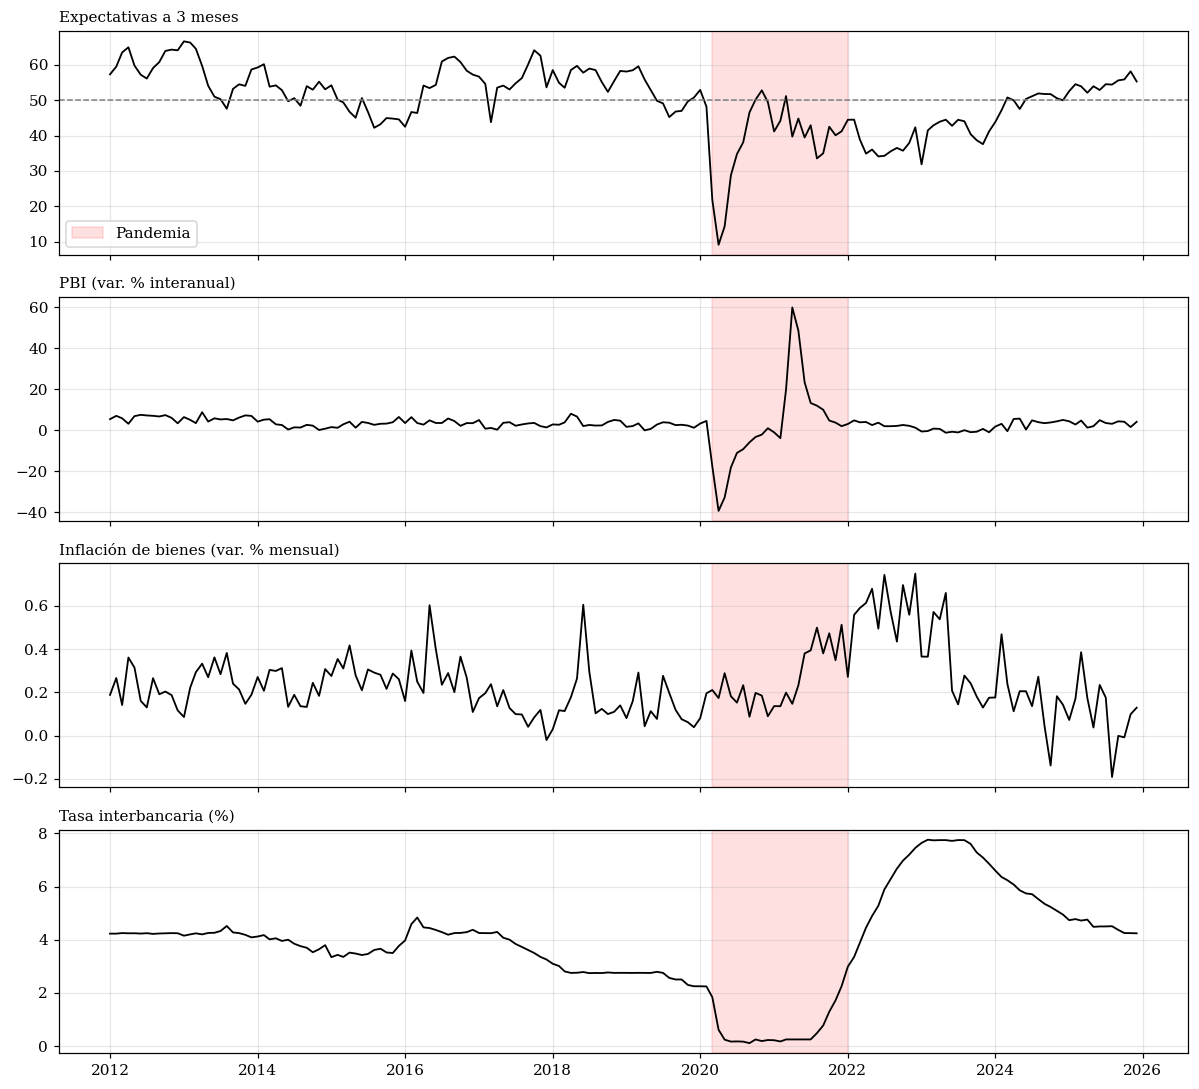

In [5]:
fig, ax = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
x = df.index.to_timestamp()
for a, c in zip(ax, [Y, PBI, INF, TIB]):
    a.plot(x, df[c], color="black", lw=1.2)
    a.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color="red", alpha=0.12, label="Pandemia")
    a.set_title(NOMBRES[c], fontsize=10, loc="left"); a.grid(alpha=0.3)
ax[0].axhline(50, color="gray", ls="--", lw=1); ax[0].legend(loc="lower left")
plt.tight_layout(); plt.show()

**Lectura:**
- Las **expectativas** estuvieron en el tramo optimista (más de 50) en 2012–2013. Cayeron a 9 puntos en abril de 2020, permanecieron en el tramo pesimista entre 2021 y 2023 y se recuperaron en 2024–2025. Su evolución es **gradual y persistente**, lo que justifica incluir sus rezagos en el modelo.
- El **PBI interanual** cae a −39 % en abril de 2020 y sube a +60 % en abril de 2021 por **efecto base**. Esto justifica el control por la pandemia.
- La **inflación de bienes** sube con fuerza en 2021–2022.
- La **tasa interbancaria** baja a casi 0 % en la pandemia y sube a 7.75 % en 2023.

### 2.3. Correlaciones simples

In [6]:
corr = df[[Y, PBI, INF, TIB]].corr()
corr.index = corr.columns = [NOMBRES[c] for c in corr.columns]
corr

,Expectativas a 3 meses,PBI (var. % interanual),Inflación de bienes (var. % mensual),Tasa interbancaria (%)
Expectativas a 3 meses,1.000,0.329,-0.371,0.066
PBI (var. % interanual),0.329,1.000,0.026,-0.047
Inflación de bienes (var. % mensual),-0.371,0.026,1.000,0.247
Tasa interbancaria (%),0.066,-0.047,0.247,1.000


## 3. Estacionariedad
Para evitar una **regresión espuria**, es decir, relaciones que aparecen solo porque las series tienen tendencia, las variables deben ser estacionarias.

### 3.1. Planteamiento de hipótesis
**Prueba ADF (Dickey–Fuller aumentada)**
- **H₀:** la serie tiene raíz unitaria, es decir, **no es estacionaria**.
- **H₁:** la serie no tiene raíz unitaria, es decir, **es estacionaria**.

**Prueba KPSS**
- **H₀:** la serie **es estacionaria**.
- **H₁:** la serie **no es estacionaria**.

Las hipótesis de ambas pruebas están **invertidas**: en la ADF, rechazar H₀ significa que la serie es estacionaria; en la KPSS, rechazar H₀ significa que **no** lo es.

### 3.2. Regla de decisión
Nivel de significación: **α = 0.05**.
- Si **p < 0.05** → **se rechaza H₀**.
- Si **p ≥ 0.05** → **no se rechaza H₀** (no hay evidencia suficiente contra H₀).

### 3.3. Cómo se combinan los resultados
| ADF | KPSS | Conclusión |
|---|---|---|
| Rechaza H₀ | No rechaza H₀ | **Estacionaria**: ambas pruebas coinciden |
| No rechaza H₀ | Rechaza H₀ | **No estacionaria**: ambas pruebas coinciden |
| Rechaza H₀ | Rechaza H₀ | **Contradictorio**: suele indicar una serie muy persistente |
| No rechaza H₀ | No rechaza H₀ | **No concluyente** |

La ADF usa constante y selección de rezagos por AIC entre 0 y 13.

### 3.4. Resultados

In [7]:
filas = []
for c in [Y, PBI, INF, TIB]:
    adf = adfuller(df[c], maxlag=13, regression="c", autolag="AIC")
    kp = kpss(df[c], regression="c", nlags="auto")
    filas.append([NOMBRES[c], adf[0], adf[1], adf[2], kp[0], kp[1]])
estac = pd.DataFrame(filas, columns=["Variable", "ADF", "ADF p", "Rezagos", "KPSS", "KPSS p"]).set_index("Variable")
estac["Veredicto"] = np.where((estac["ADF p"] < ALFA) & (estac["KPSS p"] > ALFA), "Estacionaria (ambas pruebas)",
                     np.where(estac["ADF p"] < ALFA, "Contradictorio: ADF sí, KPSS no", "No estacionaria"))
estac

,ADF,ADF p,Rezagos,KPSS,KPSS p,Veredicto
Variable,,,,,,
Expectativas a 3 meses,-3.575,0.006,1,0.714,0.012,"Contradictorio: ADF sí, KPSS no"
PBI (var. % interanual),-3.633,0.005,12,0.065,0.100,Estacionaria (ambas pruebas)
Inflación de bienes (var. % mensual),-3.071,0.029,2,0.131,0.100,Estacionaria (ambas pruebas)
Tasa interbancaria (%),-2.897,0.046,5,0.279,0.100,Estacionaria (ambas pruebas)


### 3.5. Toma de decisión por variable

In [8]:
for var, fila in estac.iterrows():
    print(f"■ {var}")
    print(f"   ADF : {ptxt(fila['ADF p'])} → {decision(fila['ADF p'])} → "
          + ("la serie ES estacionaria." if fila['ADF p'] < ALFA else "no hay evidencia de estacionariedad."))
    kp = "p ≥ 0.100 > 0.05" if fila['KPSS p'] >= 0.1 else ptxt(fila['KPSS p'])
    print(f"   KPSS: {kp} → {decision(fila['KPSS p'])} → "
          + ("la serie NO es estacionaria." if fila['KPSS p'] < ALFA else "es compatible con estacionariedad."))
    print(f"   ⇒ Conclusión: {fila['Veredicto']}")
    print()

■ Expectativas a 3 meses
   ADF : p = 0.006 < 0.05 → se rechaza H₀ → la serie ES estacionaria.
   KPSS: p = 0.012 < 0.05 → se rechaza H₀ → la serie NO es estacionaria.
   ⇒ Conclusión: Contradictorio: ADF sí, KPSS no

■ PBI (var. % interanual)
   ADF : p = 0.005 < 0.05 → se rechaza H₀ → la serie ES estacionaria.
   KPSS: p ≥ 0.100 > 0.05 → no se rechaza H₀ → es compatible con estacionariedad.
   ⇒ Conclusión: Estacionaria (ambas pruebas)

■ Inflación de bienes (var. % mensual)
   ADF : p = 0.029 < 0.05 → se rechaza H₀ → la serie ES estacionaria.
   KPSS: p ≥ 0.100 > 0.05 → no se rechaza H₀ → es compatible con estacionariedad.
   ⇒ Conclusión: Estacionaria (ambas pruebas)

■ Tasa interbancaria (%)
   ADF : p = 0.046 < 0.05 → se rechaza H₀ → la serie ES estacionaria.
   KPSS: p ≥ 0.100 > 0.05 → no se rechaza H₀ → es compatible con estacionariedad.
   ⇒ Conclusión: Estacionaria (ambas pruebas)



**Interpretación** (la KPSS reporta 0.100 cuando el p-valor real es mayor):
- **PBI, inflación y tasa interbancaria** son estacionarias según ambas pruebas, así que pueden entrar al modelo en la forma indicada. ✔
- **Expectativas**: las pruebas se contradicen (la ADF dice estacionaria y la KPSS no), lo que es típico de una serie **muy persistente**. Como el índice está acotado entre 0 y 100, no puede tener una raíz unitaria pura. La persistencia se trata **incluyendo los rezagos $Y_{t-1}$ y $Y_{t-2}$** en el modelo.

**Sobre las distintas transformaciones:** las cuatro series tienen la **misma frecuencia (mensual)** y solo difieren en cómo se expresan (nivel, variación mensual o interanual). Combinarlas es válido porque todas son estacionarias y cada forma tiene justificación: el PBI interanual elimina la estacionalidad, el índice y la tasa se usan normalmente en nivel y la inflación se usa como la publica el BCRP.

## 4. Especificación y selección de rezagos
### 4.1. Componentes del modelo
| Componente | Por qué se incluye |
|---|---|
| $PBI_t$, $INF_t$, $TIB_t$ | Variables de interés de la investigación (hipótesis específicas 1, 2 y 3) |
| $Y_{t-1}, Y_{t-2}$ | Persistencia de las expectativas: evita la autocorrelación de los residuos |
| $D^{pand}_t$ | Control de los efectos base de la pandemia (marzo 2020–diciembre 2021) |
| Errores HAC (Newey–West, 12 rezagos) | Inferencia robusta ante heterocedasticidad y autocorrelación remanente |

### 4.2. ¿Cuántos rezagos de las expectativas?
Se estima el modelo con 1, 2 y 3 rezagos y se elige el que cumple dos criterios:
1. **Menor AIC/BIC**: mejor equilibrio entre ajuste y número de parámetros.
2. **Residuos sin autocorrelación**: prueba de Breusch–Godfrey (H₀: no hay autocorrelación) **no rechazada** al 5 %.

In [9]:
def estimar(xs, data=df):
    d = data.dropna(subset=[Y] + xs)
    X = sm.add_constant(d[xs])
    mco = sm.OLS(d[Y], X).fit()
    hac = sm.OLS(d[Y], X).fit(cov_type="HAC", cov_kwds={"maxlags": 12, "use_correction": True}, use_t=True)
    return hac, mco

base_x = [PBI, INF, TIB, "pandemia"]
sel = []
for p in (1, 2, 3):
    rez = [f"Y_l{k}" for k in range(1, p + 1)]
    _, m = estimar(rez + base_x)
    sel.append([p, int(m.nobs), m.aic, m.bic] + [acorr_breusch_godfrey(m, nlags=n)[1] for n in (1, 3, 12)])
sel = pd.DataFrame(sel, columns=["Rezagos", "N", "AIC", "BIC", "BG(1) p", "BG(3) p", "BG(12) p"]).set_index("Rezagos")
sel["Sin autocorrelación (BG ≥ 0.05)"] = np.where((sel[["BG(1) p", "BG(3) p", "BG(12) p"]] >= ALFA).all(axis=1), "Sí", "No")
sel

,N,AIC,BIC,BG(1) p,BG(3) p,BG(12) p,Sin autocorrelación (BG ≥ 0.05)
Rezagos,,,,,,,
1,167,956.241,974.949,0.004,0.009,0.061,No
2,166,946.384,968.168,0.492,0.092,0.166,Sí
3,165,941.564,966.412,0.244,0.015,0.017,No


**Decisión:** el modelo con **2 rezagos** es el único en el que la prueba de Breusch–Godfrey no rechaza H₀ con 1, 3 y 12 rezagos (los residuos no están autocorrelacionados), y su BIC es menor que el del modelo con 1 rezago. Con 3 rezagos vuelve a aparecer autocorrelación y el tercer rezago no aporta. **Se elige el modelo con 2 rezagos.**

## 5. Estimación del modelo
$$Y_t = \beta_0 + \rho_1 Y_{t-1} + \rho_2 Y_{t-2} + \beta_1 PBI_t + \beta_2 INF_t + \beta_3 TIB_t + \delta\,D^{pand}_t + u_t$$
Estimación por MCO con errores estándar HAC de Newey–West (núcleo de Bartlett, 12 rezagos y corrección de muestra pequeña).

In [10]:
X_MODELO = ["Y_l1", "Y_l2", PBI, INF, TIB, "pandemia"]
modelo, modelo_mco = estimar(X_MODELO)
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                Y_EXP3M   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.807
Method:                 Least Squares   F-statistic:                     211.8
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           3.81e-73
Time:                        01:17:53   Log-Likelihood:                -466.19
No. Observations:                 166   AIC:                             946.4
Df Residuals:                     159   BIC:                             968.2
Df Model:                           6                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         17.1076      5.819      2.940      0.0

In [11]:
ic = modelo.conf_int()
cuadro = pd.DataFrame({"b": modelo.params, "EE HAC": modelo.bse, "t": modelo.tvalues, "p": modelo.pvalues,
                       "IC 95 % inf.": ic[0], "IC 95 % sup.": ic[1]})
cuadro.index = [NOMBRES[i] for i in cuadro.index]
print(f"N = {int(modelo.nobs)} | R² = {modelo_mco.rsquared:.3f} | R² ajustado = {modelo_mco.rsquared_adj:.3f}")
cuadro

N = 166 | R² = 0.814 | R² ajustado = 0.807


,b,EE HAC,t,p,IC 95 % inf.,IC 95 % sup.
Constante,17.108,5.819,2.940,0.004,5.616,28.599
Expectativas (t−1),0.919,0.106,8.641,0.000,0.709,1.129
Expectativas (t−2),-0.193,0.164,-1.178,0.241,-0.518,0.131
PBI (var. % interanual),0.067,0.086,0.784,0.434,-0.102,0.237
Inflación de bienes (var. % mensual),-5.350,1.987,-2.692,0.008,-9.275,-1.425
Tasa interbancaria (%),-0.434,0.312,-1.392,0.166,-1.049,0.182
Dummy pandemia,-5.286,2.551,-2.072,0.040,-10.323,-0.249


## 6. Contraste de hipótesis
**Regla de decisión común:** nivel de significación α = 0.05. Si **p < 0.05 se rechaza H₀**; si p ≥ 0.05, no se rechaza H₀.

### 6.1. Hipótesis general
> **Las variables macroeconómicas se asocian significativamente con las expectativas económicas a tres meses en el Perú durante el período 2012–2025.**

**Planteamiento estadístico** (prueba conjunta de Wald, F, con covarianza HAC):
- **H₀:** $\beta_1 = \beta_2 = \beta_3 = 0$ → ninguna de las tres variables macroeconómicas se asocia con las expectativas.
- **H₁:** al menos un $\beta_j \neq 0$ → al menos una de las variables se asocia significativamente con las expectativas.

Si se rechaza H₀, la hipótesis general queda **respaldada**.

In [12]:
respaldo = {}
wald = modelo.wald_test(f"{PBI} = 0, {INF} = 0, {TIB} = 0", use_f=True, scalar=True)
print(f"■ Hipótesis general: F = {wald.statistic:.3f}, {ptxt(wald.pvalue)} → {decision(wald.pvalue)}")
print("   ⇒ Al menos una de las variables macroeconómicas se asocia significativamente con las expectativas: hipótesis general RESPALDADA."
      if wald.pvalue < ALFA else "   ⇒ No hay evidencia de asociación conjunta: hipótesis general NO respaldada.")
respaldo["Hipótesis general"] = "Respaldada" if wald.pvalue < ALFA else "No respaldada"

■ Hipótesis general: F = 3.156, p = 0.026 < 0.05 → se rechaza H₀
   ⇒ Al menos una de las variables macroeconómicas se asocia significativamente con las expectativas: hipótesis general RESPALDADA.


### 6.2. Hipótesis específicas
Cada hipótesis se contrasta con la prueba *t* bilateral del coeficiente, usando errores HAC. Para que una hipótesis quede **respaldada** se deben cumplir dos condiciones: (1) que se rechace H₀ y (2) que el signo del coeficiente sea el que plantea la hipótesis.

**Hipótesis específica 1**
> El crecimiento interanual del PBI peruano presenta una asociación **positiva** y estadísticamente significativa con el índice de expectativas de la economía a tres meses en el Perú durante el período 2012–2025.
- **H₀:** $\beta_1 = 0$ → el crecimiento interanual del PBI no se asocia con las expectativas.
- **H₁:** $\beta_1 \neq 0$ → el crecimiento interanual del PBI se asocia con las expectativas (signo esperado: **positivo**).

**Hipótesis específica 2**
> La inflación subyacente mensual de bienes de Lima Metropolitana presenta una asociación **negativa** y estadísticamente significativa con el índice de expectativas de la economía a tres meses en el Perú durante el período 2012–2025.
- **H₀:** $\beta_2 = 0$ → la inflación subyacente de bienes no se asocia con las expectativas.
- **H₁:** $\beta_2 \neq 0$ → la inflación subyacente de bienes se asocia con las expectativas (signo esperado: **negativo**).

**Hipótesis específica 3**
> La tasa interbancaria promedio en moneda nacional presenta una asociación estadísticamente significativa con el índice de expectativas de la economía a tres meses en el Perú durante el período 2012–2025.
- **H₀:** $\beta_3 = 0$ → la tasa interbancaria no se asocia con las expectativas.
- **H₁:** $\beta_3 \neq 0$ → la tasa interbancaria se asocia con las expectativas (la hipótesis **no fija un signo**).

In [13]:
ESPERADO = {PBI: ("Hipótesis específica 1", "positiva"), INF: ("Hipótesis específica 2", "negativa"), TIB: ("Hipótesis específica 3", None)}
for v in [PBI, INF, TIB]:
    h, signo_esp = ESPERADO[v]
    b, p = modelo.params[v], modelo.pvalues[v]
    print(f"■ {h} – {NOMBRES[v]}: b = {b:.3f}, {ptxt(p)} → {decision(p)}")
    if p < ALFA:
        signo = "positiva" if b > 0 else "negativa"
        ok = signo_esp is None or signo == signo_esp
        print(f"   ⇒ Asociación {signo} y significativa" + ("" if signo_esp is None else (" — coincide con el signo planteado." if ok else " — signo contrario al planteado.")))
        respaldo[h] = "Respaldada" if ok else "No respaldada (signo contrario)"
    else:
        print("   ⇒ No hay evidencia suficiente de asociación: el coeficiente no se distingue de cero.")
        respaldo[h] = "No respaldada"
    print()
print("Controles:")
for v in ["Y_l1", "Y_l2", "pandemia"]:
    print(f"   {NOMBRES[v]}: b = {modelo.params[v]:.3f}, {ptxt(modelo.pvalues[v])} → {decision(modelo.pvalues[v])}")

■ Hipótesis específica 1 – PBI (var. % interanual): b = 0.067, p = 0.434 ≥ 0.05 → no se rechaza H₀
   ⇒ No hay evidencia suficiente de asociación: el coeficiente no se distingue de cero.

■ Hipótesis específica 2 – Inflación de bienes (var. % mensual): b = -5.350, p = 0.008 < 0.05 → se rechaza H₀
   ⇒ Asociación negativa y significativa — coincide con el signo planteado.

■ Hipótesis específica 3 – Tasa interbancaria (%): b = -0.434, p = 0.166 ≥ 0.05 → no se rechaza H₀
   ⇒ No hay evidencia suficiente de asociación: el coeficiente no se distingue de cero.

Controles:
   Expectativas (t−1): b = 0.919, p < 0.001 → se rechaza H₀
   Expectativas (t−2): b = -0.193, p = 0.241 ≥ 0.05 → no se rechaza H₀
   Dummy pandemia: b = -5.286, p = 0.040 < 0.05 → se rechaza H₀


### 6.3. Resumen de la contrastación

In [14]:
pd.Series(respaldo, name="Decisión").to_frame()

,Decisión
Hipótesis general,Respaldada
Hipótesis específica 1,No respaldada
Hipótesis específica 2,Respaldada
Hipótesis específica 3,No respaldada


**Explicación:**
- **Hipótesis general — respaldada:** la prueba conjunta rechaza H₀, así que al menos una de las variables macroeconómicas se asocia con las expectativas.
- **Hipótesis específica 1 (PBI) — no respaldada:** el coeficiente tiene el signo positivo planteado, pero no es significativo.
- **Hipótesis específica 2 (inflación) — respaldada:** se rechaza H₀ y el signo es negativo, como plantea la hipótesis.
- **Hipótesis específica 3 (tasa interbancaria) — no respaldada en el mismo mes:** no se rechaza H₀. En la sección 7 se verá que su efecto de largo plazo está en el límite de la significación (evidencia débil).

## 7. Efectos de largo plazo
Como el modelo incluye rezagos de las expectativas, cada coeficiente $\beta_j$ mide el efecto **en el mismo mes**. Ese efecto se acumula en los meses siguientes a través de $\rho_1$ y $\rho_2$. El **efecto de largo plazo** es:
$$\theta_j = \frac{\beta_j}{1-\rho_1-\rho_2}$$
Su error estándar se calcula con el **método delta**.

- **H₀:** $\theta_j = 0$ (no hay efecto de largo plazo).
- **H₁:** $\theta_j \neq 0$.

In [15]:
V = modelo.cov_params(); b = modelo.params
s = 1 - b["Y_l1"] - b["Y_l2"]
filas = []
for v in [PBI, INF, TIB]:
    theta = b[v] / s
    grad = pd.Series(0.0, index=b.index)
    grad[v] = 1 / s
    grad["Y_l1"] = grad["Y_l2"] = b[v] / s**2
    ee = float(np.sqrt(grad @ V @ grad))
    z = theta / ee; p = 2 * (1 - stats.t.cdf(abs(z), modelo.df_resid))
    filas.append([NOMBRES[v], b[v], theta, ee, p, decision(p)])
lp = pd.DataFrame(filas, columns=["Variable", "Corto plazo (β)", "Largo plazo (θ)", "EE (delta)", "p", "Decisión"]).set_index("Variable")
print(f"Persistencia total: ρ1 + ρ2 = {1 - s:.3f}  → el efecto de largo plazo es {1/s:.1f} veces el de corto plazo")
lp

Persistencia total: ρ1 + ρ2 = 0.726  → el efecto de largo plazo es 3.6 veces el de corto plazo


,Corto plazo (β),Largo plazo (θ),EE (delta),p,Decisión
Variable,,,,,
PBI (var. % interanual),0.067,0.245,0.270,0.365,no se rechaza H₀
Inflación de bienes (var. % mensual),-5.350,-19.510,7.651,0.012,se rechaza H₀
Tasa interbancaria (%),-0.434,-1.581,0.787,0.046,se rechaza H₀


## 8. Diagnósticos del modelo
Los diagnósticos verifican que se cumplan los **supuestos del modelo de regresión**. Si alguno falla, hay que saber **qué consecuencia tiene** y **cómo se corrige**.

**Regla de decisión común a todas las pruebas:** α = 0.05. Si **p < 0.05 se rechaza H₀**; si p ≥ 0.05, no se rechaza.

| Supuesto | Qué pasa si no se cumple | Pruebas |
|---|---|---|
| No autocorrelación | Errores estándar MCO incorrectos y posible omisión de dinámica | Breusch–Godfrey, Ljung–Box, Durbin–Watson |
| Homocedasticidad | Errores estándar MCO incorrectos (coeficientes siguen insesgados) | Breusch–Pagan–Koenker, White, ARCH |
| Normalidad de los residuos | Pruebas *t* y F inexactas en muestras pequeñas | Jarque–Bera |
| Forma funcional correcta | Coeficientes sesgados | RESET de Ramsey |
| Estabilidad de parámetros | Los coeficientes cambian en el tiempo | CUSUM |
| No multicolinealidad | Coeficientes imprecisos | VIF |

In [16]:
res = modelo_mco.resid
X = modelo_mco.model.exog
RESUMEN = []
def reportar(prueba, supuesto, estad, p, si_no_rech, si_rech):
    print(f"■ {prueba}: estadístico = {estad:.3f}, {ptxt(p)} → {decision(p)}")
    print(f"   ⇒ {si_rech if p < ALFA else si_no_rech}")
    RESUMEN.append([supuesto, prueba, estad, p, decision(p), "No cumple" if p < ALFA else "Cumple"])

### 8.1. Autocorrelación
**Qué evalúa:** si el error de un mes está relacionado con el de meses anteriores. En series de tiempo es frecuente; si existe, el modelo no está captando toda la dinámica de la variable.

**Hipótesis (Breusch–Godfrey y Ljung–Box):**
- **H₀:** no hay autocorrelación en los residuos (hasta el rezago indicado).
- **H₁:** sí hay autocorrelación.

**Durbin–Watson** no es una prueba con p-valor: su valor va de 0 a 4, y un valor **cercano a 2** indica ausencia de autocorrelación de primer orden. En modelos con rezagos de la variable dependiente, la prueba principal es **Breusch–Godfrey**, porque Durbin–Watson está sesgado hacia 2.

In [17]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson
for n in (1, 3, 12):
    lm, p, _, _ = acorr_breusch_godfrey(modelo_mco, nlags=n)
    reportar(f"Breusch–Godfrey ({n} rezago{'s' if n > 1 else ''})", "No autocorrelación", lm, p,
             "Los residuos no están autocorrelacionados.", "Los residuos están autocorrelacionados.")
lb = acorr_ljungbox(res, lags=[12])
reportar("Ljung–Box (12 rezagos)", "No autocorrelación", float(lb["lb_stat"].iloc[0]), float(lb["lb_pvalue"].iloc[0]),
         "Los residuos se comportan como ruido blanco.", "Los residuos no son ruido blanco.")
dw = durbin_watson(res)
print(f"■ Durbin–Watson = {dw:.3f} → " + ("cercano a 2: sin autocorrelación de primer orden." if 1.5 < dw < 2.5 else "alejado de 2: posible autocorrelación."))

■ Breusch–Godfrey (1 rezago): estadístico = 0.472, p = 0.492 ≥ 0.05 → no se rechaza H₀
   ⇒ Los residuos no están autocorrelacionados.
■ Breusch–Godfrey (3 rezagos): estadístico = 6.431, p = 0.092 ≥ 0.05 → no se rechaza H₀
   ⇒ Los residuos no están autocorrelacionados.
■ Breusch–Godfrey (12 rezagos): estadístico = 16.589, p = 0.166 ≥ 0.05 → no se rechaza H₀
   ⇒ Los residuos no están autocorrelacionados.
■ Ljung–Box (12 rezagos): estadístico = 10.559, p = 0.567 ≥ 0.05 → no se rechaza H₀
   ⇒ Los residuos se comportan como ruido blanco.
■ Durbin–Watson = 1.957 → cercano a 2: sin autocorrelación de primer orden.


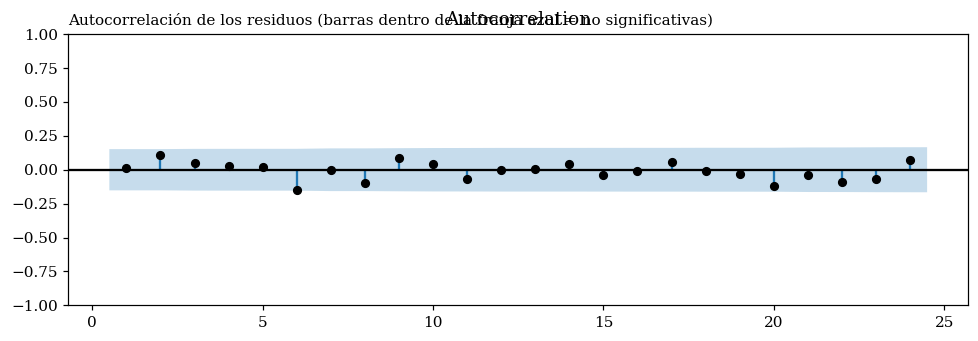

In [18]:
from statsmodels.graphics.tsaplots import plot_acf
fig, ax = plt.subplots(figsize=(9, 3.2))
plot_acf(res, lags=24, ax=ax, zero=False, color="black")
ax.set_title("Autocorrelación de los residuos (barras dentro de la franja azul = no significativas)", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

**Explicación:** ninguna prueba rechaza H₀, así que **no hay autocorrelación**. Esto es importante porque el modelo de la tesis sí la tenía (Breusch–Godfrey con p < 0.001): los dos rezagos de las expectativas recogen la dinámica que antes quedaba en los residuos. En el gráfico, casi todas las barras quedan dentro de la franja de confianza.

### 8.2. Heterocedasticidad
**Qué evalúa:** si la varianza del error es constante a lo largo de la muestra (**homocedasticidad**) o cambia (**heterocedasticidad**). Si cambia, los coeficientes siguen siendo correctos, pero sus errores estándar MCO no lo son.

| Prueba | Qué detecta | H₀ | H₁ |
|---|---|---|---|
| **Breusch–Pagan–Koenker** | Varianza que depende linealmente de los regresores (versión robusta a la no normalidad) | Homocedasticidad | Heterocedasticidad |
| **White** | Cualquier forma de heterocedasticidad (incluye cuadrados e interacciones de los regresores) | Homocedasticidad | Heterocedasticidad |
| **ARCH (12 rezagos)** | Varianza que depende de errores pasados (*clusters* de volatilidad, típico en series de tiempo) | No hay efectos ARCH | Hay efectos ARCH |

In [19]:
from statsmodels.stats.diagnostic import het_white, het_arch
bp = het_breuschpagan(res, X, robust=True)
reportar("Breusch–Pagan–Koenker", "Homocedasticidad", bp[0], bp[1],
         "La varianza de los errores es constante.", "La varianza de los errores no es constante (heterocedasticidad).")
wh = het_white(res, X)
reportar("White", "Homocedasticidad", wh[0], wh[1],
         "La varianza de los errores es constante.", "La varianza de los errores no es constante (heterocedasticidad).")
ar = het_arch(res, nlags=12)
reportar("ARCH (12 rezagos)", "Homocedasticidad", ar[0], ar[1],
         "La varianza no depende de los errores pasados.", "La varianza depende de los errores pasados (efectos ARCH).")

■ Breusch–Pagan–Koenker: estadístico = 29.828, p < 0.001 → se rechaza H₀
   ⇒ La varianza de los errores no es constante (heterocedasticidad).
■ White: estadístico = 118.434, p < 0.001 → se rechaza H₀
   ⇒ La varianza de los errores no es constante (heterocedasticidad).
■ ARCH (12 rezagos): estadístico = 11.760, p = 0.465 ≥ 0.05 → no se rechaza H₀
   ⇒ La varianza no depende de los errores pasados.


In [ ]:
d_res = df.dropna(subset=X_MODELO + [Y])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(d_res.index.to_timestamp(), res, color="black", lw=1)
ax[0].axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color="red", alpha=0.12, label="Pandemia")
ax[0].axhline(0, color="gray", lw=1); ax[0].set_title("Residuos en el tiempo", fontsize=10); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].scatter(modelo_mco.fittedvalues, res, color="black", s=12)
ax[1].axhline(0, color="gray", lw=1); ax[1].set_xlabel("Valores ajustados"); ax[1].set_ylabel("Residuos")
ax[1].set_title("Residuos vs. valores ajustados", fontsize=10); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Explicación:** las pruebas detectan **heterocedasticidad**. Los gráficos muestran la causa: los residuos son mucho más grandes en **2020–2021** (zona roja) que en el resto del período. En los meses de la pandemia la incertidumbre fue extraordinaria y el modelo se equivoca más.

**¿Cómo se corrige?** Con los **errores estándar HAC de Newey–West** que ya usa el modelo. Estos errores son válidos aunque haya heterocedasticidad (y autocorrelación), así que **las pruebas t y F del modelo siguen siendo confiables**. Los coeficientes no cambian, porque la heterocedasticidad no los sesga.

### 8.3. Normalidad de los residuos
**Qué evalúa:** si los errores siguen una distribución normal, revisando su asimetría y curtosis (colas).
- **H₀:** los residuos siguen una distribución normal.
- **H₁:** los residuos no siguen una distribución normal.

■ Jarque–Bera: estadístico = 169.951, p < 0.001 → se rechaza H₀
   ⇒ Los residuos no son normales.
   Asimetría = -1.12 (normal = 0) | Curtosis = 7.42 (normal = 3)


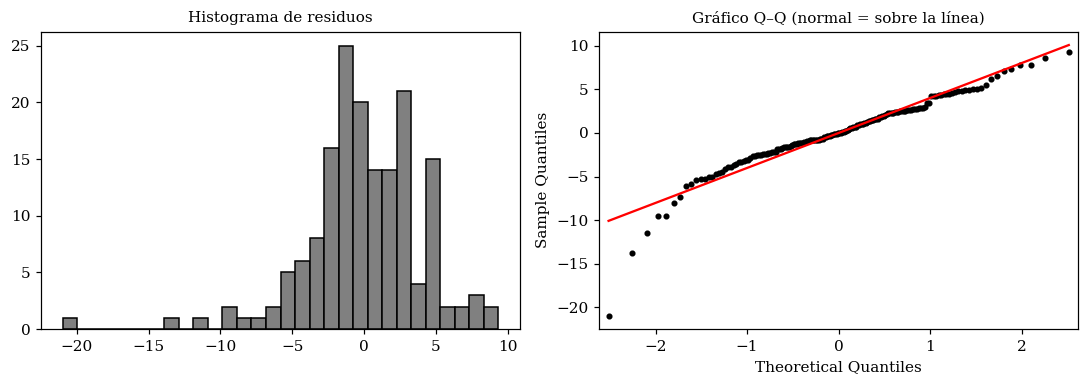

In [20]:
jb, jbp, asim, curt = jarque_bera(res)
reportar("Jarque–Bera", "Normalidad", jb, jbp, "Los residuos son normales.", "Los residuos no son normales.")
print(f"   Asimetría = {asim:.2f} (normal = 0) | Curtosis = {curt:.2f} (normal = 3)")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(res, bins=30, color="gray", edgecolor="black"); ax[0].set_title("Histograma de residuos", fontsize=10)
sm.qqplot(res, line="s", ax=ax[1], markerfacecolor="black", markeredgecolor="black", markersize=3)
ax[1].set_title("Gráfico Q–Q (normal = sobre la línea)", fontsize=10)
plt.tight_layout(); plt.show()

**Explicación:** se rechaza la normalidad. La curtosis es mucho mayor que 3: hay **colas pesadas**, es decir, unos pocos errores muy grandes. En el gráfico Q–Q, los puntos se alejan de la línea en los extremos; corresponden a los meses de la pandemia (abril y mayo de 2020, por ejemplo).

**¿Es grave?** No en este caso. Con **166 observaciones**, el teorema central del límite hace que los coeficientes MCO tengan una distribución aproximadamente normal aunque los errores no lo sean, y los errores HAC mantienen la validez de la inferencia. La no normalidad es una **limitación a reportar**, no un problema que invalide el modelo.

### 8.4. Forma funcional (especificación)
**Qué evalúa:** si la relación lineal es adecuada o si faltan términos no lineales. La prueba RESET agrega el cuadrado de los valores ajustados y verifica si aporta.
- **H₀:** la forma funcional es correcta (no faltan términos no lineales).
- **H₁:** hay un error de especificación.

In [21]:
rs = linear_reset(modelo_mco, power=2, use_f=True)
reportar("RESET de Ramsey", "Forma funcional correcta", float(rs.fvalue), float(rs.pvalue),
         "La forma lineal es adecuada; no faltan términos no lineales.", "Hay un error de especificación.")

■ RESET de Ramsey: estadístico = 2.559, p = 0.112 ≥ 0.05 → no se rechaza H₀
   ⇒ La forma lineal es adecuada; no faltan términos no lineales.


**Explicación:** no se rechaza H₀. La forma lineal del modelo es adecuada y no hay evidencia de que falten términos no lineales.

### 8.5. Estabilidad de los parámetros
**Qué evalúa:** si los coeficientes se mantienen constantes a lo largo de 2012–2025 o si hay un **cambio estructural**. La prueba CUSUM acumula los errores de predicción: si la línea sale de las bandas de confianza, los parámetros no son estables.
- **H₀:** los parámetros son estables.
- **H₁:** hay inestabilidad (cambio estructural).

■ CUSUM: estadístico = 0.950, p = 0.328 ≥ 0.05 → no se rechaza H₀
   ⇒ Los coeficientes son estables en el período.


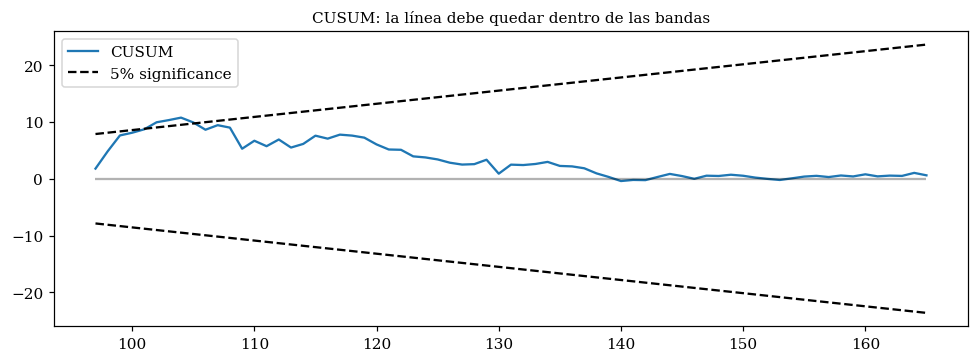

In [22]:
cs = breaks_cusumolsresid(res, ddof=len(modelo.params))
reportar("CUSUM", "Estabilidad de parámetros", cs[0], cs[1],
         "Los coeficientes son estables en el período.", "Hay un cambio estructural en los coeficientes.")
d_rls = df.dropna(subset=X_MODELO + [Y])
rls = sm.RecursiveLS(d_rls[Y].values, sm.add_constant(d_rls[X_MODELO]).values).fit()
fig = rls.plot_cusum(figsize=(9, 3.4)); fig.axes[0].set_title("CUSUM: la línea debe quedar dentro de las bandas", fontsize=10)
plt.tight_layout(); plt.show()

**Explicación:** no se rechaza H₀ y la línea CUSUM queda dentro de las bandas. Los coeficientes son **estables** en todo el período: las asociaciones estimadas valen para toda la muestra y no solo para una parte.

### 8.6. Multicolinealidad
**Qué evalúa:** si las variables explicativas están tan relacionadas entre sí que no se puede separar el efecto de cada una. Se mide con el **factor de inflación de la varianza (VIF)**; no es una prueba con hipótesis, sino un criterio:
- **VIF < 5:** sin problema. **Entre 5 y 10:** moderado. **VIF > 10:** grave.

In [23]:
vif = pd.Series({NOMBRES[c]: variance_inflation_factor(X, i) for i, c in enumerate(modelo_mco.model.exog_names) if c != "const"}, name="VIF")
display(vif.to_frame())
for k, v in vif.items():
    print(f"■ {k}: VIF = {v:.2f} → " + ("sin problema." if v < 5 else "moderado." if v < 10 else "grave."))

,VIF
Expectativas (t−1),5.576
Expectativas (t−2),5.027
PBI (var. % interanual),1.204
Inflación de bienes (var. % mensual),1.303
Tasa interbancaria (%),2.657
Dummy pandemia,3.294


■ Expectativas (t−1): VIF = 5.58 → moderado.
■ Expectativas (t−2): VIF = 5.03 → moderado.
■ PBI (var. % interanual): VIF = 1.20 → sin problema.
■ Inflación de bienes (var. % mensual): VIF = 1.30 → sin problema.
■ Tasa interbancaria (%): VIF = 2.66 → sin problema.
■ Dummy pandemia: VIF = 3.29 → sin problema.


**Explicación:** las **tres variables de interés** (PBI, inflación y tasa interbancaria) tienen VIF bajos, así que sus coeficientes se estiman con precisión. Los rezagos de las expectativas tienen VIF moderados (≈ 5) porque $Y_{t-1}$ y $Y_{t-2}$ se parecen mucho entre sí, lo que es normal en un modelo autorregresivo y no afecta a las variables de interés.

### 8.7. Resumen de los diagnósticos

In [24]:
resumen = pd.DataFrame(RESUMEN, columns=["Supuesto", "Prueba", "Estadístico", "p", "Decisión", "Resultado"]).set_index(["Supuesto", "Prueba"])
resumen

Estadístico     p  \
Supuesto                  Prueba                                            
No autocorrelación        Breusch–Godfrey (1 rezago)          0.472 0.492   
                          Breusch–Godfrey (3 rezagos)         6.431 0.092   
                          Breusch–Godfrey (12 rezagos)       16.589 0.166   
                          Ljung–Box (12 rezagos)             10.559 0.567   
Homocedasticidad          Breusch–Pagan–Koenker              29.828 0.000   
                          White                             118.434 0.000   
                          ARCH (12 rezagos)                  11.760 0.465   
Normalidad                Jarque–Bera                       169.951 0.000   
Forma funcional correcta  RESET de Ramsey                     2.559 0.112   
Estabilidad de parámetros CUSUM                               0.950 0.328   

                                                                Decisión  \
Supuesto                  Prueba                                           
No autocorrelación        Breusch–Godfrey (1 rezago)    no se rechaza H₀   
                          Breusch–Godfrey (3 rezagos)   no se rechaza H₀   
                          Breusch–Godfrey (12 rezagos)  no se rechaza H₀   
                          Ljung–Box (12 rezagos)        no se rechaza H₀   
Homocedasticidad          Breusch–Pagan–Koenker            se rechaza H₀   
                          White                            se rechaza H₀   
                          ARCH (12 rezagos)             no se rechaza H₀   
Normalidad                Jarque–Bera                      se rechaza H₀   
Forma funcional correcta  RESET de Ramsey               no se rechaza H₀   
Estabilidad de parámetros CUSUM                         no se rechaza H₀   

                                                        Resultado  
Supuesto                  Prueba                                   
No autocorrelación        Breusch–Godfrey (1 rezago)       Cumple  
                          Breusch–Godfrey (3 rezagos)      Cumple  
                          Breusch–Godfrey (12 rezagos)     Cumple  
                          Ljung–Box (12 rezagos)           Cumple  
Homocedasticidad          Breusch–Pagan–Koenker         No cumple  
                          White                         No cumple  
                          ARCH (12 rezagos)                Cumple  
Normalidad                Jarque–Bera                   No cumple  
Forma funcional correcta  RESET de Ramsey                  Cumple  
Estabilidad de parámetros CUSUM                            Cumple

**Conclusión de los diagnósticos:**
| Supuesto | ¿Se cumple? | Tratamiento |
|---|---|---|
| No autocorrelación | ✔ Sí | Resuelto con los rezagos de las expectativas |
| Homocedasticidad | ✘ No (pandemia) | Errores estándar HAC de Newey–West |
| Normalidad | ✘ No (colas pesadas por la pandemia) | Muestra grande + errores HAC; se reporta como limitación |
| Forma funcional | ✔ Sí | — |
| Estabilidad | ✔ Sí | — |
| Multicolinealidad | ✔ Sin problema en las variables de interés | — |

**El modelo es válido para la inferencia:** los supuestos que fallan (homocedasticidad y normalidad) se deben a los meses de la pandemia y quedan cubiertos por los errores HAC.

## 9. Ajuste e interpretación
### 9.1. Valores observados y ajustados

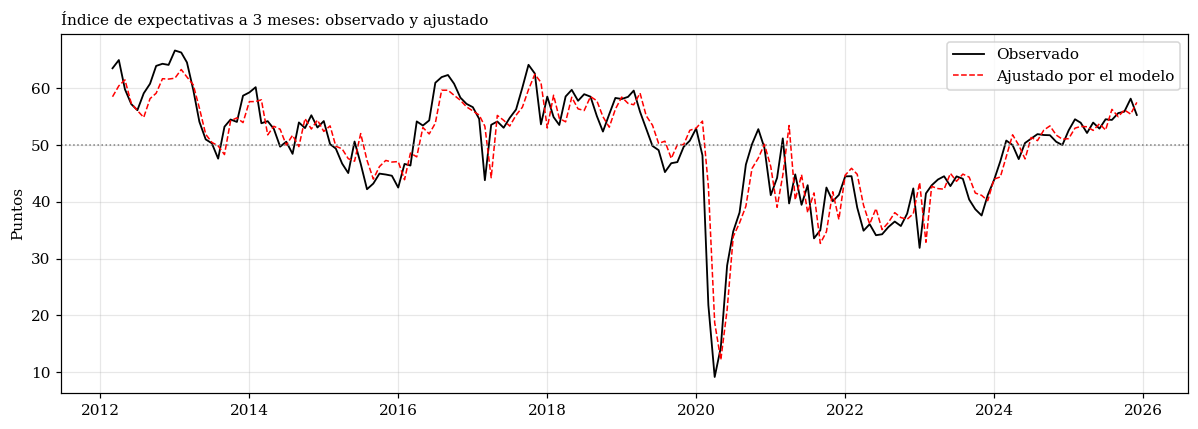

In [25]:
d = df.dropna(subset=X_MODELO + [Y])
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(d.index.to_timestamp(), d[Y], color="black", lw=1.2, label="Observado")
ax.plot(d.index.to_timestamp(), modelo.fittedvalues, color="red", lw=1, ls="--", label="Ajustado por el modelo")
ax.axhline(50, color="gray", ls=":", lw=1); ax.set_ylabel("Puntos"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Índice de expectativas a 3 meses: observado y ajustado", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

### 9.2. Coeficientes de las variables de interés (corto y largo plazo)

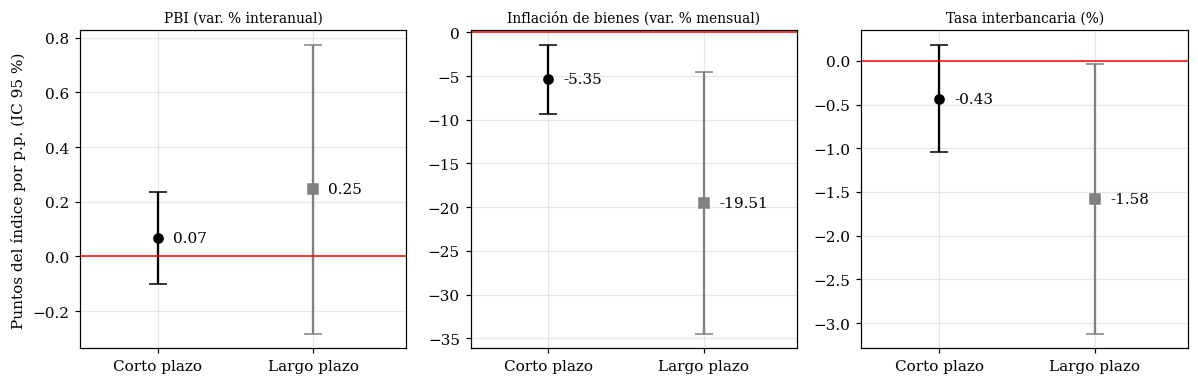

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
for a, v in zip(ax, [PBI, INF, TIB]):
    lo, hi = modelo.conf_int().loc[v]; bb = modelo.params[v]
    a.errorbar(0, bb, yerr=[[bb - lo], [hi - bb]], fmt="o", color="black", capsize=6)
    a.annotate(f"{bb:.2f}", (0, bb), xytext=(10, 0), textcoords="offset points", va="center")
    th = lp.loc[NOMBRES[v], "Largo plazo (θ)"]; e = 1.96 * lp.loc[NOMBRES[v], "EE (delta)"]
    a.errorbar(1, th, yerr=e, fmt="s", color="gray", capsize=6)
    a.annotate(f"{th:.2f}", (1, th), xytext=(10, 0), textcoords="offset points", va="center")
    a.axhline(0, color="red", lw=1); a.set_xticks([0, 1]); a.set_xticklabels(["Corto plazo", "Largo plazo"])
    a.set_xlim(-0.5, 1.6); a.set_title(NOMBRES[v], fontsize=9); a.grid(alpha=0.3)
ax[0].set_ylabel("Puntos del índice por p.p. (IC 95 %)")
plt.tight_layout(); plt.show()

In [27]:
bi = modelo.params[INF]; ti = lp.loc[NOMBRES[INF], "Largo plazo (θ)"]
print(f"■ Inflación: un aumento de 0.1 p.p. en la inflación mensual de bienes se asocia con {bi*0.1:.2f} puntos")
print(f"  en el índice ese mismo mes y con {ti*0.1:.2f} puntos en el largo plazo, manteniendo lo demás constante.")
print(f"■ R² = {modelo_mco.rsquared:.3f}: el modelo recoge el {modelo_mco.rsquared*100:.1f} % de la variabilidad de las expectativas.")

■ Inflación: un aumento de 0.1 p.p. en la inflación mensual de bienes se asocia con -0.54 puntos
  en el índice ese mismo mes y con -1.95 puntos en el largo plazo, manteniendo lo demás constante.
■ R² = 0.814: el modelo recoge el 81.4 % de la variabilidad de las expectativas.


**Interpretación económica:**
- **Inflación (hipótesis específica 2):** es la única variable macroeconómica con una asociación **negativa y significativa**, tanto en el mismo mes como en el largo plazo. Mayores presiones sobre los precios de los bienes se acompañan de expectativas empresariales menos favorables. Como la inflación mensual de bienes suele moverse en décimas, un aumento de 0.1 p.p. es la referencia más realista para interpretar el coeficiente.
- **PBI (hipótesis específica 1):** el coeficiente es positivo, como se esperaba, pero **no significativo**. Una vez que se controlan la persistencia y la pandemia, el crecimiento interanual del PBI no aporta información adicional sobre las expectativas.
- **Tasa interbancaria (hipótesis específica 3):** **no significativa en el mismo mes** (p = 0.166). En el **largo plazo** su efecto acumulado es negativo y apenas significativo al 5 % (θ ≈ −1.6; p = 0.046), así que hay **evidencia débil** de que tasas más altas se acompañan de expectativas algo menos favorables con el tiempo. Como el resultado está en el límite y la tasa también responde a la coyuntura, debe interpretarse con cautela.
- **Persistencia:** las expectativas dependen mucho de su propio pasado ($\rho_1+\rho_2 \approx 0.73$), lo que explica que los efectos se acumulen en el tiempo.
- **Pandemia:** reduce el índice en unos 5 puntos adicionales, más allá de lo que explican las demás variables.

## 10. Conclusiones
1. Las cuatro series son **mensuales** y compatibles con estacionariedad. La persistencia de las expectativas se trata con **dos rezagos**, que eliminan la autocorrelación de los residuos.
2. **Hipótesis general — respaldada:** la prueba conjunta de Wald indica que al menos una de las variables macroeconómicas se asocia significativamente con las expectativas.
3. **Hipótesis específica 2 (inflación) — respaldada:** la inflación subyacente de bienes tiene una asociación **negativa y significativa** con las expectativas, en el corto y en el largo plazo.
4. **Hipótesis específica 1 (PBI) — no respaldada:** el signo es positivo, pero no significativo.
5. **Hipótesis específica 3 (tasa interbancaria) — no respaldada en el corto plazo.** En el largo plazo aparece una asociación negativa en el límite de la significación (p = 0.046), que se considera evidencia débil.
6. **Diagnósticos:** el modelo no tiene autocorrelación, su forma funcional es correcta y sus parámetros son estables. Presenta heterocedasticidad y residuos no normales por los meses de la pandemia, lo que se corrige con errores HAC. Explica alrededor del **81 %** de la variabilidad del índice.
7. **Relación con la tesis:** el modelo final **confirma el resultado central de la tesis** (la inflación es la única variable significativa) con una especificación más completa, que corrige la autocorrelación y el efecto de la pandemia.

*Limitaciones:* el estudio es **asociativo**, no causal. El índice es muy persistente y no se modelan rezagos de las variables explicativas ni la disponibilidad de la información en tiempo real.

## 11. Textos para el artículo
### 11.1. Metodología – Especificación empírica
> Se estima un modelo autorregresivo que incorpora dos rezagos del índice de expectativas y una variable dicotómica para la pandemia (marzo de 2020–diciembre de 2021): $Y_t = \beta_0 + \rho_1 Y_{t-1} + \rho_2 Y_{t-2} + \beta_1 PBI_t + \beta_2 INF_t + \beta_3 TIB_t + \delta D^{pand}_t + u_t$. Los rezagos recogen la elevada persistencia del índice y la variable dicotómica controla los efectos base del PBI durante la emergencia sanitaria. El número de rezagos se eligió con los criterios AIC y BIC y con la prueba de Breusch–Godfrey. Las series tienen frecuencia mensual y son compatibles con estacionariedad según las pruebas ADF y KPSS. El modelo se estima por MCO con errores estándar HAC de Newey–West con 12 rezagos, y los efectos de largo plazo se calculan como $\beta_j/(1-\rho_1-\rho_2)$, con errores estándar obtenidos por el método delta.

### 11.2. Resultados
> La inflación subyacente mensual de bienes presenta una asociación negativa y estadísticamente significativa con las expectativas (b = −5.350; p = 0.008), cuyo efecto de largo plazo es de alrededor de −19.5 puntos por punto porcentual. El crecimiento interanual del PBI (b = 0.067; p = 0.434) y la tasa interbancaria (b = −0.434; p = 0.166) no son significativos al 5 % en el corto plazo; en el largo plazo, la tasa interbancaria muestra una asociación negativa en el límite de la significación (θ = −1.581; p = 0.046). La prueba conjunta de Wald respalda la hipótesis general. Los rezagos de las expectativas reflejan una persistencia elevada ($\rho_1+\rho_2 \approx 0.73$) y la variable de pandemia es negativa y significativa. El modelo explica el 81 % de la variabilidad del índice; las pruebas de Breusch–Godfrey y Ljung–Box no detectan autocorrelación, RESET no indica errores de forma funcional y CUSUM no detecta inestabilidad. Las pruebas de Breusch–Pagan–Koenker, White y Jarque–Bera indican heterocedasticidad y residuos no normales, concentrados en los meses de la pandemia, por lo que la inferencia se basa en errores HAC.

### 11.3. Limitaciones
> El modelo es asociativo y no identifica relaciones causales. El índice de expectativas es muy persistente —la prueba KPSS rechaza su estacionariedad, aunque la ADF no—, los residuos son heterocedásticos y no normales por los meses de la pandemia, y no se modelan rezagos de las variables macroeconómicas ni la disponibilidad de la información en tiempo real.

> ⚠ **Importante:** estos textos **reemplazan** los resultados del modelo de la tesis en el artículo. Antes de cambiar el artículo, el grupo, Venancio y el docente deben estar de acuerdo, porque los coeficientes ya no coincidirán con los de la tesis (aunque las conclusiones sí).